# RoadVision AI — Model Evaluation

Evaluates one trained checkpoint: precision, recall, mAP@0.5, mAP@0.5:0.95, per-class metrics, confusion matrix, PR/F1 curves and detection examples.

**Constraints:**
- Weights: `RV_WEIGHTS_PATH`, else the best `mAP50-95` row of `reports/experiment_comparison.csv` (from 07), else the baseline `best.pt`.
- Validation metrics use `conf=0.001` (Ultralytics default). The confusion matrix and the example images use a higher threshold (`RV_CONF`, default 0.25).
- Validation was used for checkpoint selection, so these numbers are optimistic. The test split is evaluated only with `RV_EVAL_TEST=1` and only if it exists.

In [1]:
from pathlib import Path
import os, json, random, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2, torch
from ultralytics import YOLO
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DEFAULT_ROOT = Path.home() / ".cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned"
CLEAN_ROOT = Path(os.getenv("ROADVISION_CLEANED_ROOT", str(DEFAULT_ROOT))).expanduser().resolve()
if not CLEAN_ROOT.is_dir():
    raise FileNotFoundError(f"Prepared dataset not found: {CLEAN_ROOT}. Set ROADVISION_CLEANED_ROOT.")
DATA_YAML = CLEAN_ROOT / "roadvision_prepared.yaml"  # produced by 04_dataset_preparation.ipynb
if not DATA_YAML.is_file():
    raise FileNotFoundError(f"{DATA_YAML} not found. Run 04_dataset_preparation.ipynb first.")
_cfg = yaml.safe_load(DATA_YAML.read_text(encoding="utf-8"))
_names = _cfg["names"]
CLASS_NAMES = [_names[k] for k in sorted(_names, key=int)] if isinstance(_names, dict) else list(_names)
NC = len(CLASS_NAMES)
SPLITS = {s: CLEAN_ROOT / s for s in ("train", "valid", "test")}
RUNS_DIR = CLEAN_ROOT / "training_runs"
REPORT_DIR = CLEAN_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORKERS = 2
MIN_EVAL_INSTANCES = 20  # classes with fewer val instances give statistically meaningless AP

def count_instances(label_dir, nc):
    counts = np.zeros(nc, dtype=int)
    for f in Path(label_dir).glob("*.txt"):
        for line in f.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) == 5: counts[int(float(parts[0]))] += 1
    return counts

BATCH = 16
CONF_VIEW = float(os.getenv("RV_CONF", 0.25))

def resolve_weights():
    env = os.getenv("RV_WEIGHTS_PATH")
    if env: return Path(env).expanduser()
    csv = REPORT_DIR / "experiment_comparison.csv"
    if csv.is_file():
        df = pd.read_csv(csv)
        df = df[df["status"] == "ok"].sort_values("mAP50-95", ascending=False)
        for w in df["best_weights"]:
            if Path(w).is_file(): return Path(w)
    return RUNS_DIR / "yolov8n_baseline" / "weights" / "best.pt"

WEIGHTS = resolve_weights()
if not WEIGHTS.is_file(): raise FileNotFoundError(f"Weights not found: {WEIGHTS}")
model = YOLO(str(WEIGHTS))
try: IMGSZ = int(os.getenv("RV_IMGSZ", model.ckpt["train_args"]["imgsz"]))
except Exception: IMGSZ = 640
EVAL_DIR = RUNS_DIR / "evaluation" / WEIGHTS.parent.parent.name
EVAL_DIR.mkdir(parents=True, exist_ok=True)
print("Weights:", WEIGHTS, "| imgsz:", IMGSZ, "| classes:", NC)

Weights: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/training_runs/yolov8n_baseline/weights/best.pt | imgsz: 640 | classes: 21


## 1. Validation metrics

In [2]:
def evaluate(split):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS, plots=True,
                     project=str(EVAL_DIR.parent), name=f"{EVAL_DIR.name}_{split}", exist_ok=True)

def overall_metrics(m):
    b = m.box
    return {"precision": float(b.mp), "recall": float(b.mr), "mAP@0.5": float(b.map50), "mAP@0.5:0.95": float(b.map),
            "ms_preprocess": float(m.speed["preprocess"]), "ms_inference": float(m.speed["inference"]), "ms_postprocess": float(m.speed["postprocess"])}

val_m = evaluate("val")
val_overall = overall_metrics(val_m)
display(pd.Series(val_overall, name="val").round(4).to_frame())

Ultralytics 8.4.193 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 11913MiB)
Model summary (fused): 73 layers, 3,137,567 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1089.7±292.4 MB/s, size: 37.6 KB)
val: Scanning /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/valid/labels.cache... 300 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 44.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 1.9it/s 10.3s.4s
                   all        300       2560      0.691      0.383      0.436      0.269
               bicycle         30         32      0.654        0.5      0.523       0.22
                   bus        218        423      0.838      0.514      0.672      0.437
                   car        232        842      0.802      0.677      0.767      0.504
               minibus

,val
precision,0.6905
recall,0.3834
mAP@0.5,0.4356
mAP@0.5:0.95,0.2685
ms_preprocess,1.4853
ms_inference,4.8394
ms_postprocess,8.1022


## 2. Per-class metrics
`evaluable` = at least `MIN_EVAL_INSTANCES` val instances. Macro averages use only evaluable classes. `missed_%` is the share of ground-truth objects with no detection at the confusion-matrix threshold.

,class_id,class,train_instances,eval_instances,P,R,mAP50,mAP50-95,missed_%,evaluable
12,12,policecar,31,1,1.000,0.000,0.000,0.000,0.000,False
14,14,scooter,37,1,1.000,0.000,0.004,0.000,0.000,False
20,20,wheelbarrow,111,8,1.000,0.000,0.087,0.052,0.000,False
19,19,van,693,62,0.201,0.211,0.215,0.132,0.000,True
15,15,suv,798,59,0.326,0.305,0.231,0.161,0.000,True
11,11,pickup,1081,142,0.658,0.244,0.369,0.210,4.225,True
9,9,minivan,822,109,0.524,0.364,0.375,0.263,0.917,True
10,10,motorbike,1948,335,0.640,0.463,0.494,0.160,12.537,True
8,8,minibus,93,2,0.335,0.500,0.495,0.446,0.000,False
3,3,bicycle,427,32,0.654,0.500,0.523,0.220,9.375,True


Macro over 11 evaluable classes: {'mAP50': 0.5127, 'mAP50-95': 0.3055, 'P': 0.618, 'R': 0.4602}
Absent from val: ['ambulance', 'army vehicle', 'auto rickshaw', 'garbagevan', 'human hauler']
Not evaluable (<20 instances): ['minibus', 'policecar', 'scooter', 'taxi', 'wheelbarrow']


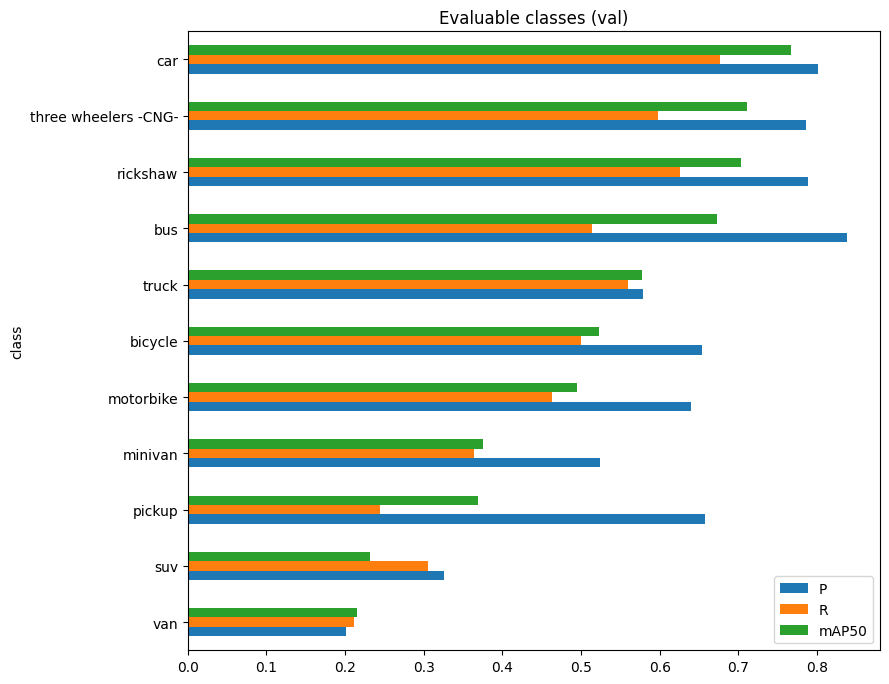

In [3]:
def per_class_table(m, split_dir):
    box = m.box
    cm = m.confusion_matrix.matrix  # [pred, true]; index NC = background
    df = pd.DataFrame({"class_id": range(NC), "class": CLASS_NAMES,
                       "train_instances": count_instances(SPLITS["train"] / "labels", NC),
                       "eval_instances": count_instances(Path(split_dir) / "labels", NC),
                       "P": np.nan, "R": np.nan, "mAP50": np.nan, "mAP50-95": np.nan})
    for k, cid in enumerate(box.ap_class_index):
        df.loc[df.class_id == int(cid), ["P", "R", "mAP50", "mAP50-95"]] = list(box.class_result(k))
    gt = cm[:, :NC].sum(0)
    df["missed_%"] = np.where(gt > 0, 100 * cm[NC, :NC] / np.maximum(gt, 1), np.nan)
    df["evaluable"] = df["eval_instances"] >= MIN_EVAL_INSTANCES
    return df

def macro(df):
    ev = df[df["evaluable"]]
    return {"n_classes": int(len(ev)), "mAP50": float(ev["mAP50"].mean()), "mAP50-95": float(ev["mAP50-95"].mean()),
            "P": float(ev["P"].mean()), "R": float(ev["R"].mean())}

val_pc = per_class_table(val_m, SPLITS["valid"])
display(val_pc.sort_values("mAP50").round(3))
val_macro = macro(val_pc)
print(f"Macro over {val_macro['n_classes']} evaluable classes:", {k: round(v, 4) for k, v in val_macro.items() if k != "n_classes"})
print("Absent from val:", val_pc.loc[val_pc.eval_instances == 0, "class"].tolist())
print(f"Not evaluable (<{MIN_EVAL_INSTANCES} instances):", val_pc.loc[(val_pc.eval_instances > 0) & ~val_pc.evaluable, "class"].tolist())
val_pc.to_csv(EVAL_DIR / "per_class_val.csv", index=False)

ev = val_pc[val_pc.evaluable].sort_values("mAP50")
ax = ev.set_index("class")[["P", "R", "mAP50"]].plot.barh(figsize=(9, 0.45 * len(ev) + 2))
ax.set_title("Evaluable classes (val)"); plt.tight_layout(); plt.show()

## 3. Confusion matrix
Rows and columns follow Ultralytics: predicted vs ground-truth class, plus a background entry (false positives and missed objects).

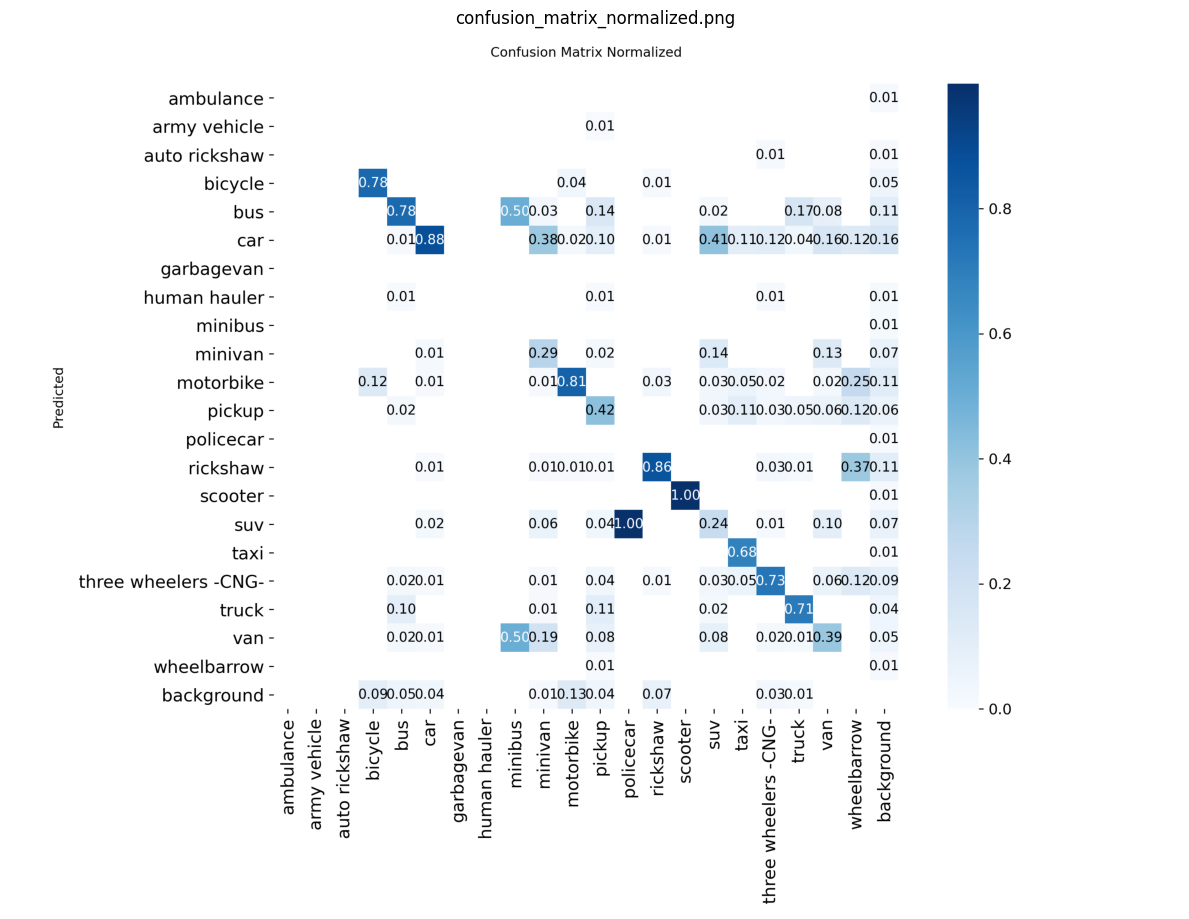

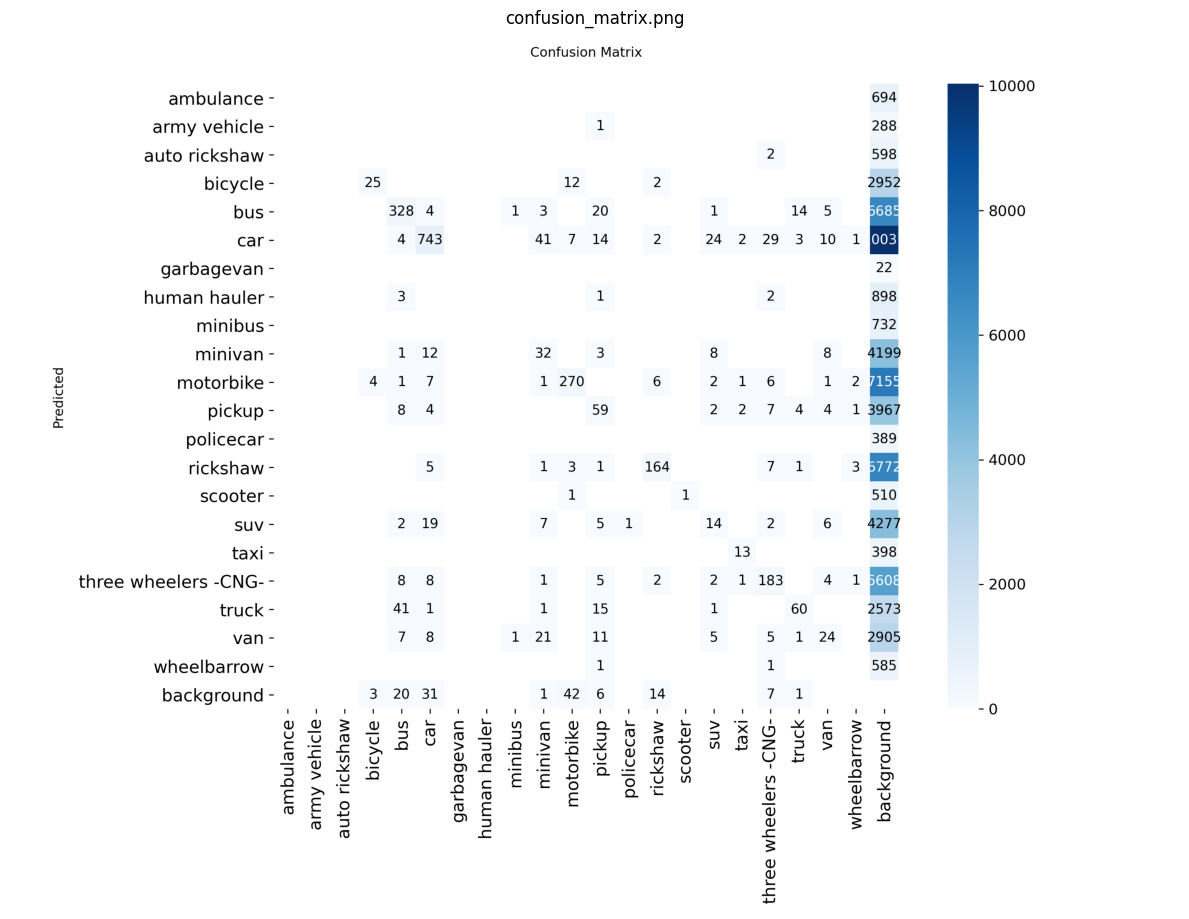

Top class confusions:


,true,predicted_as,count,share_of_true_%
8,bus,truck,41,9.7
22,minivan,car,41,37.6
62,three wheelers -CNG-,car,29,11.6
50,suv,car,24,40.7
28,minivan,van,21,19.3
34,pickup,bus,20,14.1
15,car,suv,19,2.3
41,pickup,truck,15,10.6
35,pickup,car,14,9.9
70,truck,bus,14,16.7


Background errors (false positives / missed objects):


,class,false_positives_on_background,missed_objects
10,motorbike,7155,42
5,car,10037,31
4,bus,6685,20
13,rickshaw,6772,14
17,three wheelers -CNG-,5608,7
11,pickup,3967,6
3,bicycle,2952,3
9,minivan,4199,1
18,truck,2573,1
1,army vehicle,288,0


In [4]:
VAL_DIR = Path(val_m.save_dir)
for fname in ("confusion_matrix_normalized.png", "confusion_matrix.png"):
    p = VAL_DIR / fname
    if p.is_file():
        plt.figure(figsize=(12, 10)); plt.imshow(mpimg.imread(str(p))); plt.axis("off"); plt.title(fname); plt.tight_layout(); plt.show()

cm = val_m.confusion_matrix.matrix
M = cm[:NC, :NC].copy(); np.fill_diagonal(M, 0)
gt_total = cm[:, :NC].sum(0)
pairs = [{"true": CLASS_NAMES[t], "predicted_as": CLASS_NAMES[p], "count": int(M[p, t]), "share_of_true_%": 100 * M[p, t] / max(gt_total[t], 1)}
         for t in range(NC) for p in range(NC) if M[p, t] > 0]
top_conf = pd.DataFrame(pairs).sort_values("count", ascending=False).head(15)
print("Top class confusions:")
display(top_conf.round(1))
bg = pd.DataFrame({"class": CLASS_NAMES, "false_positives_on_background": cm[:NC, NC].astype(int), "missed_objects": cm[NC, :NC].astype(int)})
print("Background errors (false positives / missed objects):")
display(bg.sort_values("missed_objects", ascending=False).head(10))
top_conf.to_csv(EVAL_DIR / "top_confusions_val.csv", index=False)

## 4. PR and F1 curves

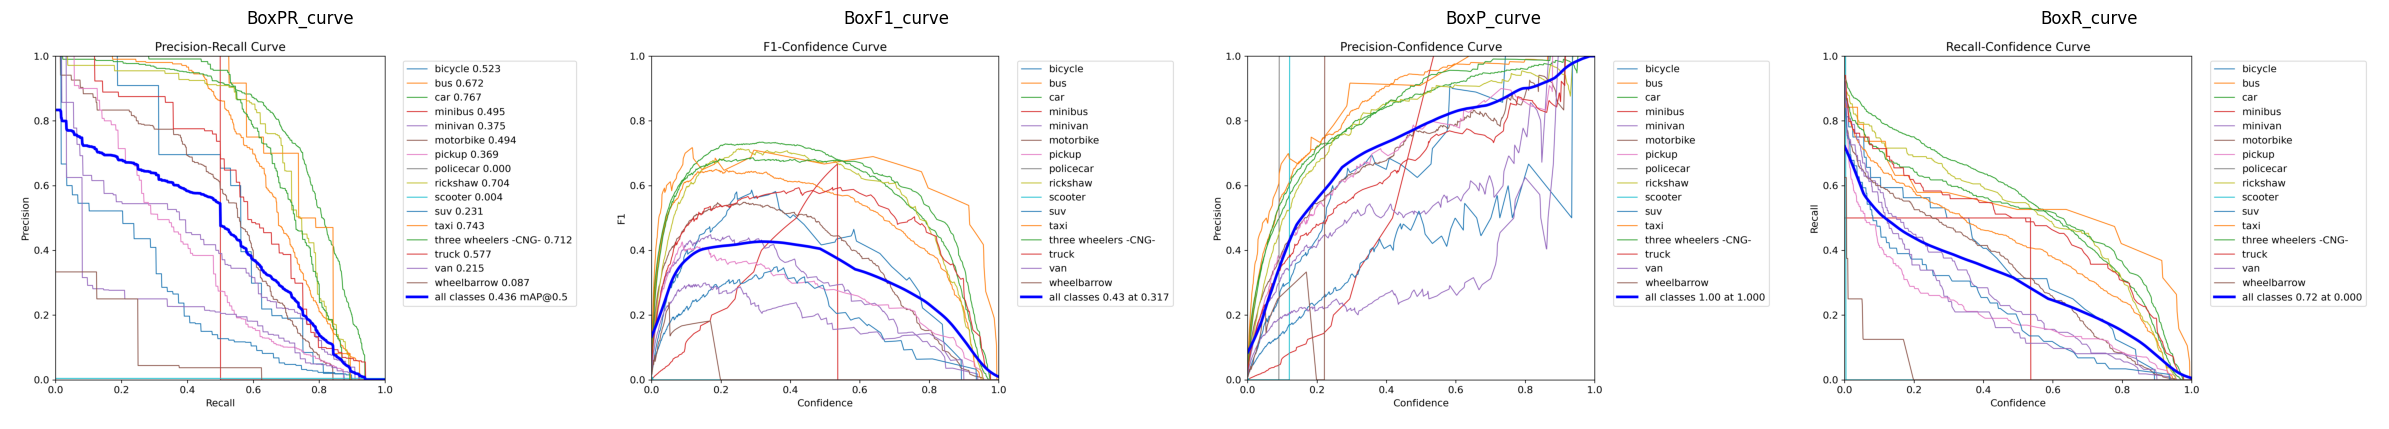

In [5]:
curves = [VAL_DIR / f for f in ("BoxPR_curve.png", "BoxF1_curve.png", "BoxP_curve.png", "BoxR_curve.png")]
curves = [c for c in curves if c.is_file()]
if curves:
    fig, axes = plt.subplots(1, len(curves), figsize=(6 * len(curves), 5), squeeze=False)
    for ax, c in zip(axes[0], curves):
        ax.imshow(mpimg.imread(str(c))); ax.axis("off"); ax.set_title(c.stem)
    plt.tight_layout(); plt.show()
else:
    print("No curve images found in", VAL_DIR)

## 5. Detection examples
Left: ground truth. Right: prediction at `RV_CONF`. First a random sample, then images containing the classes in `RV_WEAK` (default: van, suv, pickup, minivan).

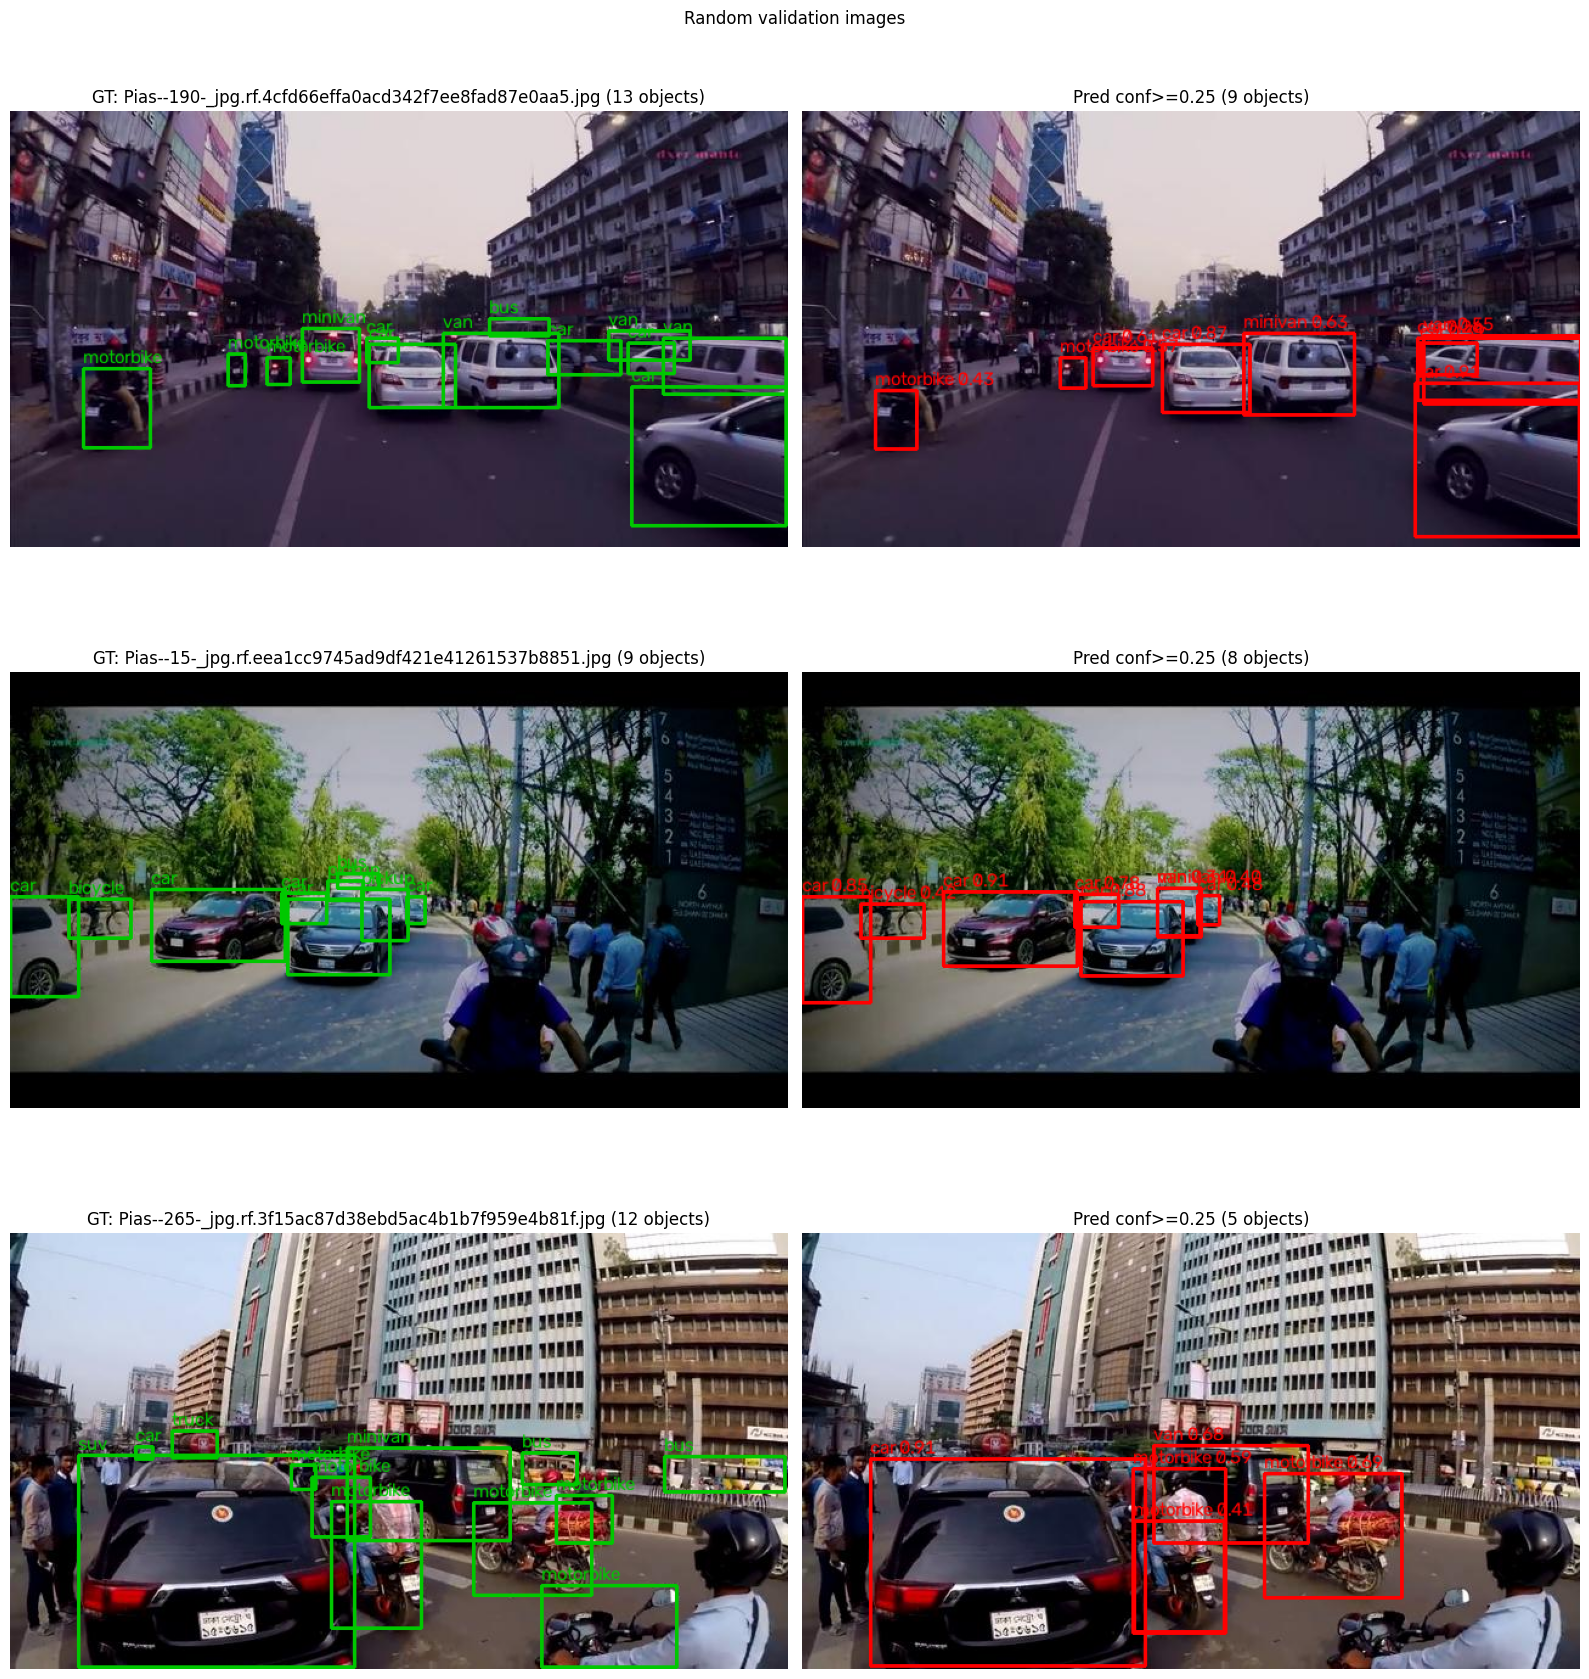

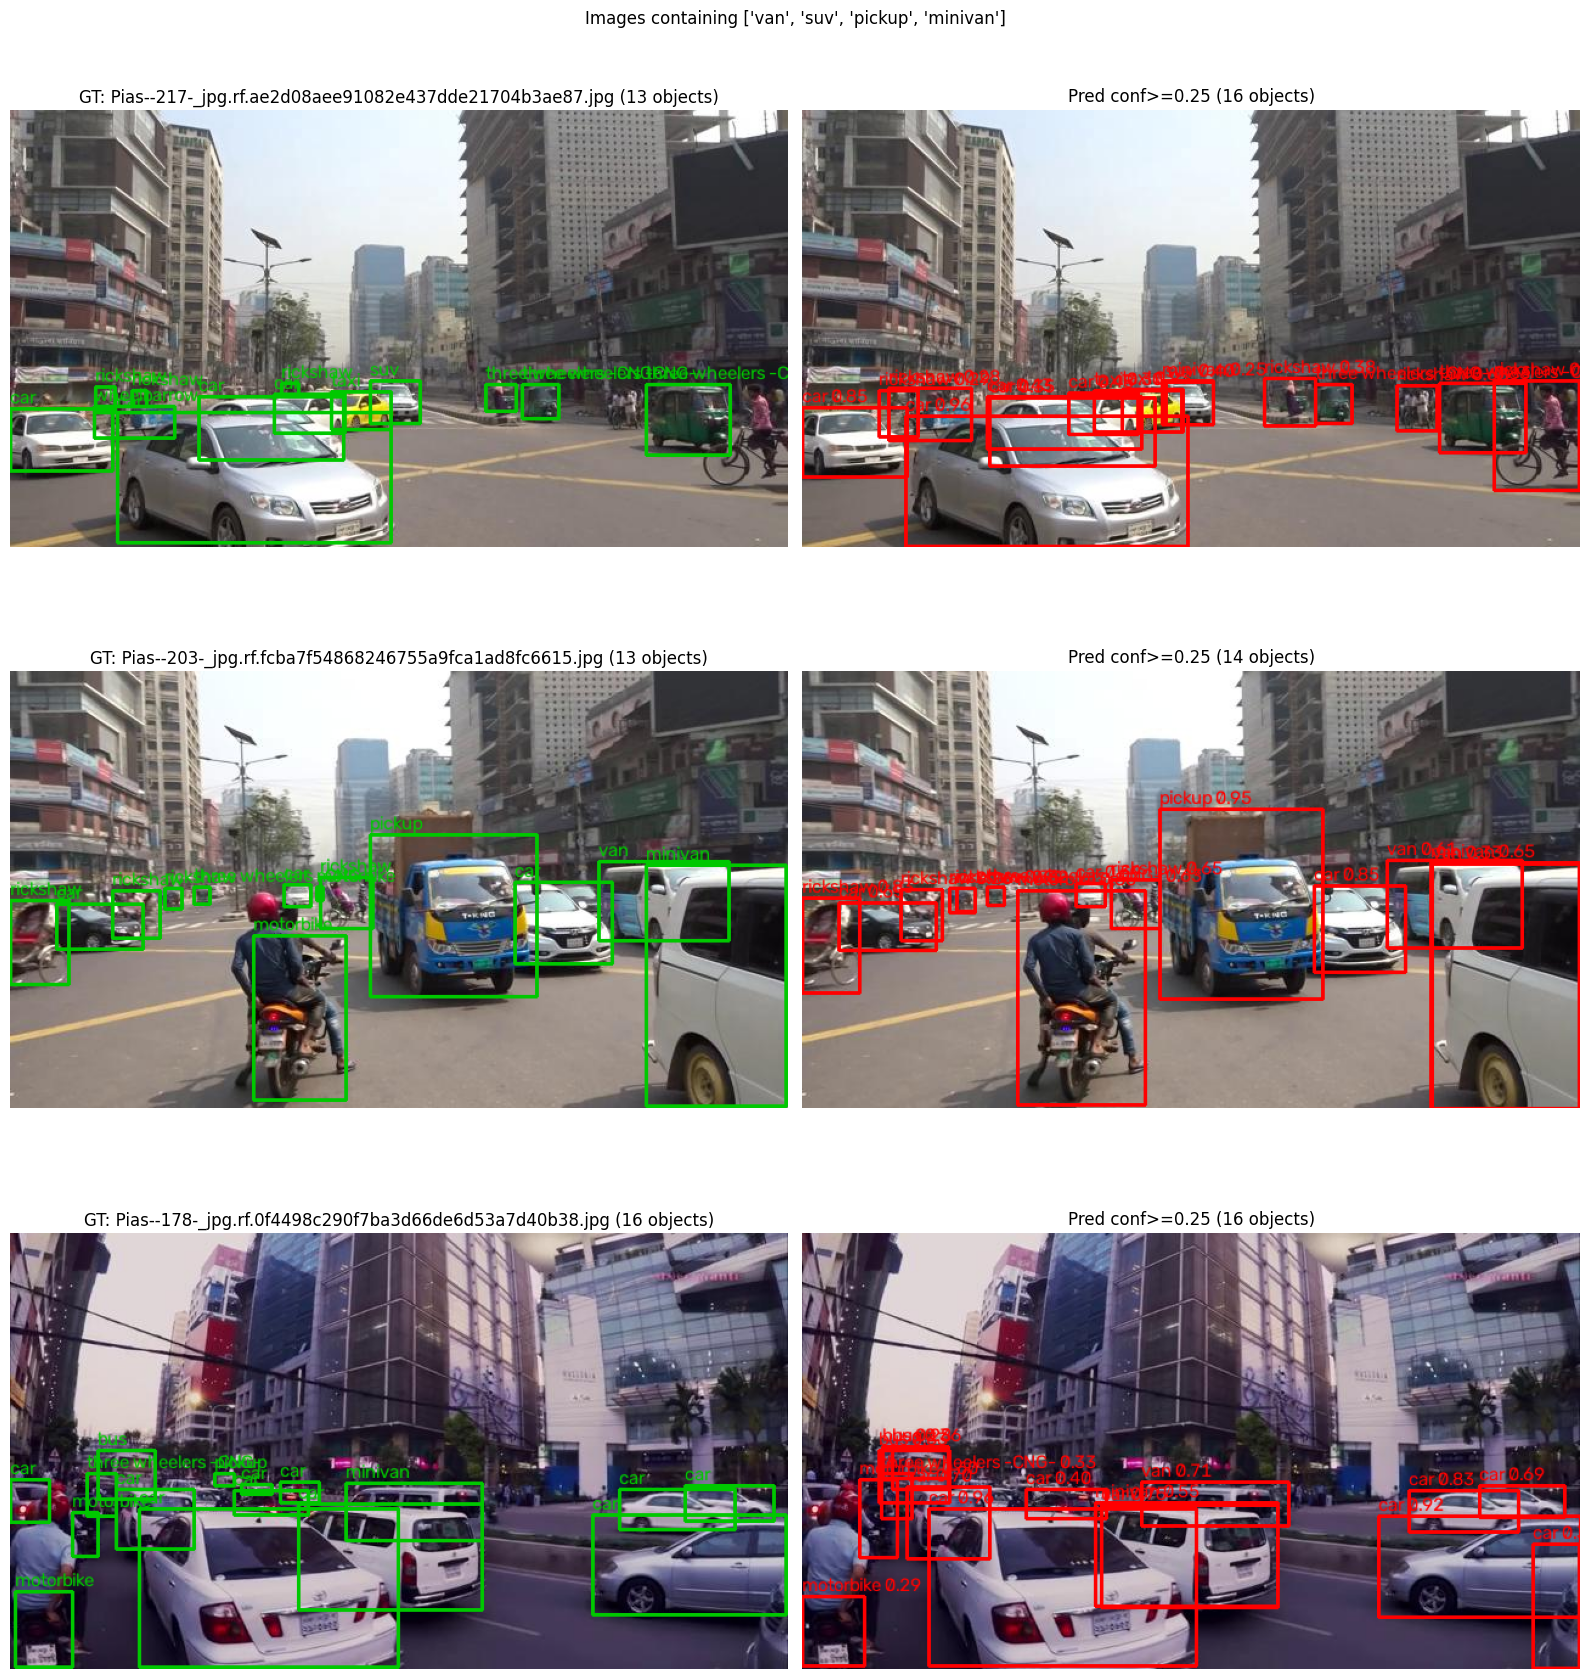

In [6]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
rng = random.Random(SEED)

def read_gt(img_path):
    lbl = img_path.parent.parent / "labels" / (img_path.stem + ".txt")
    rows = []
    if lbl.is_file():
        for line in lbl.read_text(encoding="utf-8").splitlines():
            p = line.split()
            if len(p) == 5: rows.append((int(float(p[0])), *map(float, p[1:])))
    return rows

def draw(img, boxes, color):
    out = img.copy()
    for cls, x1, y1, x2, y2, conf in boxes:
        x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
        txt = CLASS_NAMES[cls] + (f" {conf:.2f}" if conf is not None else "")
        cv2.putText(out, txt, (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)
    return out

def show_pairs(paths, title):
    if not paths: print("No images for:", title); return
    fig, axes = plt.subplots(len(paths), 2, figsize=(16, 6 * len(paths)), squeeze=False)
    for row, p in zip(axes, paths):
        img = cv2.imread(str(p)); h, w = img.shape[:2]
        gt = [(c, (xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h, None) for c, xc, yc, bw, bh in read_gt(p)]
        r = model.predict(str(p), imgsz=IMGSZ, conf=CONF_VIEW, device=DEVICE, verbose=False)[0]
        pr = [(int(c), *xy, float(s)) for c, xy, s in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist(), r.boxes.conf.tolist())]
        row[0].imshow(cv2.cvtColor(draw(img, gt, (0, 200, 0)), cv2.COLOR_BGR2RGB)); row[0].set_title(f"GT: {p.name} ({len(gt)} objects)")
        row[1].imshow(cv2.cvtColor(draw(img, pr, (0, 0, 255)), cv2.COLOR_BGR2RGB)); row[1].set_title(f"Pred conf>={CONF_VIEW} ({len(pr)} objects)")
        for a in row: a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

val_imgs = sorted(p for p in (SPLITS["valid"] / "images").iterdir() if p.suffix.lower() in IMG_EXT)
show_pairs(rng.sample(val_imgs, min(3, len(val_imgs))), "Random validation images")

WEAK = [w.strip() for w in os.getenv("RV_WEAK", "van,suv,pickup,minivan").split(",")]
weak_ids = {CLASS_NAMES.index(w) for w in WEAK if w in CLASS_NAMES}
weak_imgs = [p for p in val_imgs if any(r[0] in weak_ids for r in read_gt(p))]
show_pairs(rng.sample(weak_imgs, min(3, len(weak_imgs))), f"Images containing {WEAK}")

## 6. Optional: held-out test split
Runs only with `RV_EVAL_TEST=1` and only if `test/images` exists. Evaluate once, after the configuration is final.

In [7]:
test_overall = test_macro = None
if os.getenv("RV_EVAL_TEST", "0") == "1" and (SPLITS["test"] / "images").is_dir():
    test_m = evaluate("test")
    test_overall = overall_metrics(test_m)
    test_pc = per_class_table(test_m, SPLITS["test"])
    test_macro = macro(test_pc)
    display(pd.Series(test_overall, name="test").round(4).to_frame())
    display(test_pc.sort_values("mAP50").round(3))
    test_pc.to_csv(EVAL_DIR / "per_class_test.csv", index=False)
elif not (SPLITS["test"] / "images").is_dir():
    print("No test split found. Test evaluation skipped.")
else:
    print("Test evaluation skipped (set RV_EVAL_TEST=1).")

No test split found. Test evaluation skipped.


## 7. Save the evaluation report

In [8]:
report = {"weights": str(WEIGHTS), "imgsz": IMGSZ, "data_yaml": str(DATA_YAML),
          "val": val_overall, "val_macro_evaluable_classes": val_macro,
          "val_images": len(val_imgs), "test": test_overall, "test_macro_evaluable_classes": test_macro}
(EVAL_DIR / "evaluation_report.json").write_text(json.dumps(report, indent=2, default=float), encoding="utf-8")
print(json.dumps(report, indent=2, default=float))
print("Saved to:", EVAL_DIR)

{
  "weights": "/root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/training_runs/yolov8n_baseline/weights/best.pt",
  "imgsz": 640,
  "data_yaml": "/root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/roadvision_prepared.yaml",
  "val": {
    "precision": 0.6905058961152799,
    "recall": 0.38343154837465915,
    "mAP@0.5": 0.43557661473648535,
    "mAP@0.5:0.95": 0.26853803527930165,
    "ms_preprocess": 1.48527426024278,
    "ms_inference": 4.839424360931541,
    "ms_postprocess": 8.102231466133768
  },
  "val_macro_evaluable_classes": {
    "n_classes": 11,
    "mAP50": 0.5127269100345457,
    "mAP50-95": 0.3055366760378156,
    "P": 0.6179684710688279,
    "R": 0.4601670040088532
  },
  "val_images": 300,
  "test": null,
  "test_macro_evaluable_classes": null
}
Saved to: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/training_run